# PSV PROJECT - Random Forest

This is the first notebook which will be using Random Forest. The data of this project is on the folder raw- images and the tabular data is on pandas labeled-dataset.csv
First we need to create virtual enviroment, in this case is called  'nahiavenv' 
Afterwards, we need to download all the needed libraries. Such as :pandas, scikit-learn, numpy

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import joblib
import re


BASE_DIR   = r"c:\Users\Nahia\OneDrive - Office 365 Fontys\ICT\SEMESTER 3\PSV project"
DATA_DIR   = os.path.join(BASE_DIR, "data")
IMAGES_DIR = os.path.join(BASE_DIR, "raw_images")
MODELS_DIR = os.path.join(BASE_DIR, "models")
print(BASE_DIR)

### Loading and Preparing the Dataset

The first step in the pipeline is loading and preparing the dataset for training. The dataset consists of images collected from Instagram posts and manually labelled into different categories. The image paths and corresponding labels are stored in a CSV file.

In [ ]:
df = pd.read_csv(os.path.join(DATA_DIR, "multilabel_dataset.csv"))
df.head()

,image_path,shortcode,likes,timestamp,caption,comment_count,category,PLAYER,ACTION,GRAPHIC,CROWD,CELEBRATION
0,raw_images/DMhd4aiMXhj_0.jpg,DMhd4aiMXhj,10223,2025-07-25 09:47:28,"#OttenInnovationCup, het eerste podium voor gr...",17,graphic_post,1,0,1,0,0
1,raw_images/DMhd4aiMXhj_1.jpg,DMhd4aiMXhj,10223,2025-07-25 09:47:28,"#OttenInnovationCup, het eerste podium voor gr...",17,graphic_post,1,0,1,0,0
2,raw_images/DMhd4aiMXhj_2.jpg,DMhd4aiMXhj,10223,2025-07-25 09:47:28,"#OttenInnovationCup, het eerste podium voor gr...",17,graphic_post,1,0,1,0,0
3,raw_images/DMhd4aiMXhj_3.jpg,DMhd4aiMXhj,10223,2025-07-25 09:47:28,"#OttenInnovationCup, het eerste podium voor gr...",17,graphic_post,1,0,1,0,0
4,raw_images/DMj9VcQs0SB_0.jpg,DMj9VcQs0SB,13198,2025-07-26 09:00:00,Provisional squad numbers? We’ve got you. 👕,66,graphic_post,1,0,1,0,0


### Timestamp
Extract temporal features from the full datetime: hour, day of the week, month,
and whether the post was published on a weekend. These capture posting time patterns
that influence engagement.

In [15]:

df["timestamp"] = pd.to_datetime(df["timestamp"])

df["hour"]       = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek   # 0=Monday, 6=Sunday
df["month"]      = df["timestamp"].dt.month
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)


### Caption
Extract text-based features from the raw caption: length, word count, hashtag and
mention count, emoji presence, and exclamation marks.

In [16]:

def extract_caption_features(text):
    if pd.isna(text):
        text = ""
    return {
        "caption_length":    len(text),
        "word_count":        len(text.split()),
        "hashtag_count":     len(re.findall(r"#\w+", text)),
        "mention_count":     len(re.findall(r"@\w+", text)),
        "has_emoji":         int(bool(re.search(r"[^\w\s,.\-!?']", text))),
        "exclamation_count": text.count("!"),
    }

caption_features = df["caption"].apply(extract_caption_features).apply(pd.Series)
df = pd.concat([df, caption_features], axis=1)

### Define Features & Target
Combine image labels, caption features, and timestamp features into a single feature
matrix. The target variable is the exact like count.

In [17]:

LABEL_COLS   = ["CROWD", "CELEBRATION", "GRAPHIC", "PLAYER", "ACTION"]
CAPTION_COLS = list(caption_features.columns)
TIME_COLS    = ["hour", "day_of_week", "month", "is_weekend"]

FEATURE_COLS = LABEL_COLS + CAPTION_COLS + TIME_COLS
TARGET       = "likes"

X = df[FEATURE_COLS]
y = df[TARGET]

### Train / Test Split
Split the dataset into 80% training and 20% test sets with a fixed random seed
for reproducibility.

In [18]:

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.176, random_state=42 
)


### Random Forest
Train a Random Forest Regressor with 200 trees. The model learns non-linear
relationships between post features and like count without requiring feature scaling.

In [19]:

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

### Evaluation
Evaluate the model using MAE (average error in likes), RMSE (penalizes large errors),
and R² (proportion of variance explained).

In [20]:

y_pred = rf.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")


MAE:  2341.33
RMSE: 6597.14
R²:   0.9460


### Feature Importance
Rank all input features by their contribution to the model's predictions. Useful for
identifying which signals (image content, caption, or timing) drive engagement the most

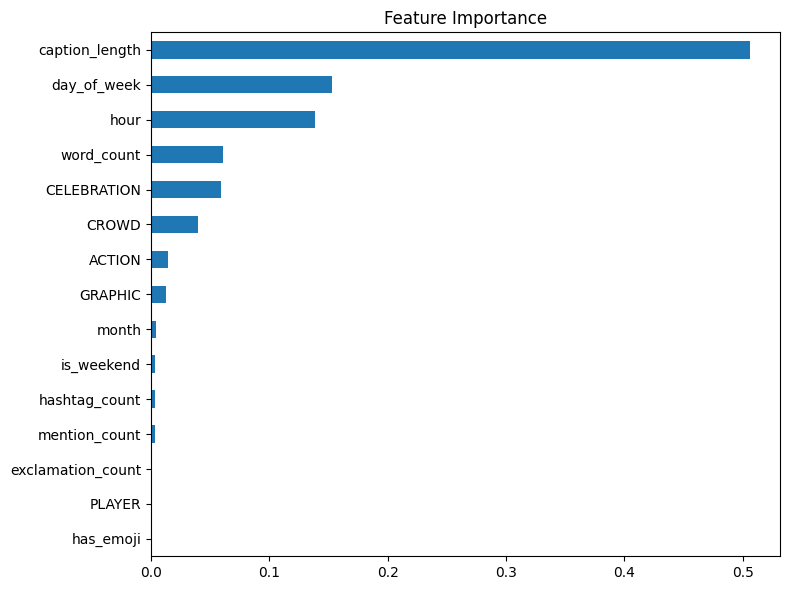

In [21]:

import matplotlib.pyplot as plt

importances = pd.Series(rf.feature_importances_, index=FEATURE_COLS)
importances.sort_values(ascending=True).plot(
    kind="barh", figsize=(8, 6), title="Feature Importance"
)
plt.tight_layout()
plt.show()

### Error Analysis
Visualize the error distribution, actual vs predicted likes, and residuals to identify
where the model struggles. The top 10 worst predictions are printed to surface
potential outliers or systematic biases.

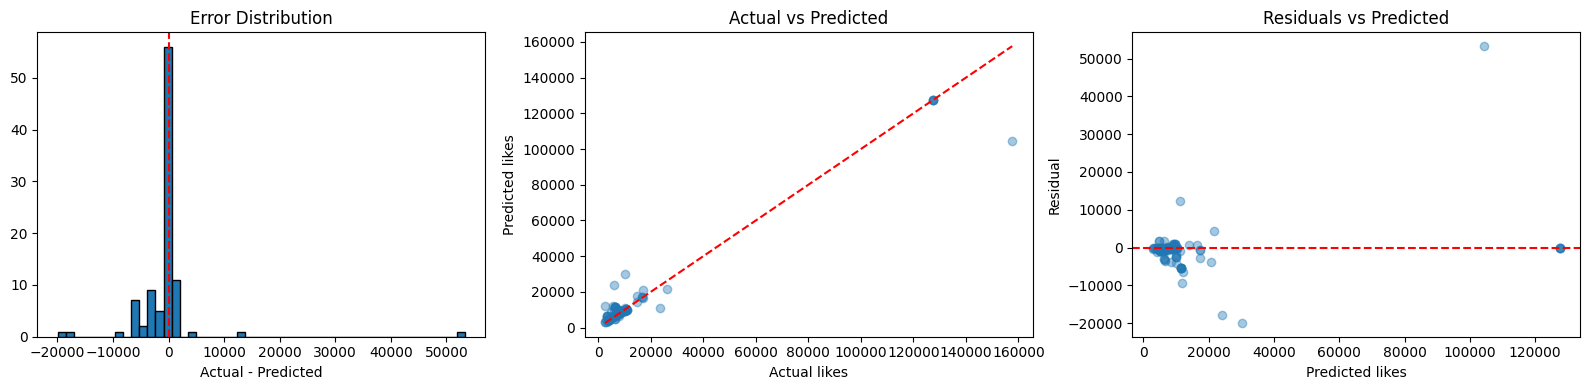

Top 10 worst predictions:
    actual  predicted         error     abs_error
30  157626   104337.0  53288.584845  53288.584845
90   10197    30150.0 -19953.024292  19953.024292
14    6046    24000.0 -17953.894845  17953.894845
74   23567    11222.0  12345.438869  12345.438869
23    2614    11961.0  -9347.372212   9347.372212
88    5776    12211.0  -6434.582486   6434.582486
70    6279    11625.0  -5346.373786   5346.373786
71    6279    11625.0  -5346.373786   5346.373786
29    6279    11584.0  -5305.138179   5305.138179
67    6279    11584.0  -5305.138179   5305.138179


In [22]:

errors = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Error distribution
axes[0].hist(errors, bins=50, edgecolor="black")
axes[0].set_title("Error Distribution")
axes[0].set_xlabel("Actual - Predicted")
axes[0].axvline(0, color="red", linestyle="--")

# Actual vs Predicted
axes[1].scatter(y_test, y_pred, alpha=0.4)
axes[1].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], "r--")
axes[1].set_title("Actual vs Predicted")
axes[1].set_xlabel("Actual likes")
axes[1].set_ylabel("Predicted likes")

# Residuals vs Predicted
axes[2].scatter(y_pred, errors, alpha=0.4)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_title("Residuals vs Predicted")
axes[2].set_xlabel("Predicted likes")
axes[2].set_ylabel("Residual")

plt.tight_layout()
plt.show()

results_df = pd.DataFrame({
    "actual":    y_test.values,
    "predicted": y_pred.round(),
    "error":     errors.values,
    "abs_error": np.abs(errors.values)
})

print("Top 10 worst predictions:")
print(results_df.nlargest(10, "abs_error"))

In [23]:

# ── 9. Save Model ─────────────────────────────────────────────────────────────
os.makedirs(MODELS_DIR, exist_ok=True)
joblib.dump(rf, os.path.join(MODELS_DIR, "random_forest_likes.pkl"))

['c:\\Users\\Nahia\\OneDrive - Office 365 Fontys\\ICT\\SEMESTER 3\\PSV project\\models\\random_forest_likes.pkl']